# Parallelizing the training environment

> #### AI usage disclaimer
> This notebook was started by the AI and I've refactored it to increase readability.  
> The agent wrote all of this code and optimized the single-vehicle environment.

The single-vehicle environment from notebook 02 works, but it is slow: about 4 FPS (varies with spawn point). The game itself runs at 20 FPS with no client attached, so the physics are not the bottleneck. Every `step()` performs a handful of **blocking** request/response round trips over the socket, and each one costs a TCP send, game-thread processing, and a TCP receive.

There are two independent improvements: (1) cut the round trips per step, and (2) spread the work across N vehicles or N instances. Section 1 covers the first. For the second there are two options:

- **Option A: N vehicles in one instance.** One BeamNG.tech process, one socket, N vehicles, each with its own sensor suite, stepped in lockstep by one shared `step(1)`.
- **Option B: N instances with `AsyncVectorEnv`.** N separate game processes (potentially on separate GPUs), one car each, parallelized across cores by Gymnasium. Described in section 10 as the scale-out path.

We will explore Option A first: it reuses one game process, validates the whole vector-environment plumbing (group spawn, per-vehicle sensors, lockstep step, respawn), and amortizes the single `step(1)` round trip across N vehicles. Option B is the scale-out path once Option A's single-thread ceiling is hit.


## Setup


In [1]:
import os
import sys
import time
import random

import numpy as np
import gymnasium as gym
from gymnasium import spaces

import matplotlib.pyplot as plt
%matplotlib inline

# single-vehicle environment and constants from notebook 02
sys.path.insert(0, os.path.abspath("../src/env/gymnasium"))
from beamng_tech_env.envs.beamng_tech import (
    BeamNGTechEnv,
    drift_from_state,
    DRIFT_CARS_6SPEED,
    DRIFT_MIN_ANGLE, DRIFT_MAX_ANGLE, DRIFT_MIN_AIRSPEED,
    IMU_ACC_MAX, IMU_ANGVEL_MAX, ANGLE_MAX, AIRSPEED_MAX_KPH,
    BEV_N, Z_LO, Z_HI,
    car_rotation,
    lidar_bev,
    LIDAR_RES_V, LIDAR_V_ANGLE, LIDAR_HZ, LIDAR_MAX_DIST, LIDAR_DENSITY,
    DAMAGE_LIMIT, EPISODE_TIMEOUT, FPS, MIN_SPEED,
)

from beamngpy import BeamNGpy, Scenario, Vehicle
from beamngpy.sensors import AdvancedIMU, Damage, Electrics, Lidar

print("imports ok")


imports ok


## Where time wastes away

The single-vehicle environment from notebook 02 measured about 4 to 7 FPS (150 ms/step).  
The old `BeamNGTechEnv.step()` had these python <-> game synchronization points:

| Call | Mechanism |
|---|---|
| `ego.control(...)` | ack |
| `beamng.control.step(1)` | ack |
| `ego.sensors.poll()` | bundled `State` + `Electrics` + `Damage` vehicle sensors |
| `imu.poll()` | `PollAdvancedImuVE` |

These four synchronisation points each pause the game just to synchronize the game with python over the socket connection.

`State` is always present as a sensor, by default attached by BeamNGpy.

## Optimizations implemented

The AI agent improved the deterministic loop with the following changes:

1. **Skipped or replaced acknowledgements**  
In the environment step function, we send `Control` and wait for its ack (so the tick runs with the new input), then send `Step` then the bundled sensor request as one batch (no ack) and collect the sensor data, so the sensors are read after the actions changed the game state; `state["time"]` is checked to increase as a confirmation the game actually stepped, in the negative case it catches a stale read and re-polls once.
3. **Dropped the IMU round trip**:  
`imu_acc`/`imu_angvel` are derived from two consecutive `State` snapshots (kinematic d(vel)/dt in the car frame, plus the rotation-vector angular velocity).
5. **Improved the BEV LiDAR input and calculation**:  
The LiDAR read skips the unused colour buffer and numpy is used more extensively now in the BEV function.
7. **Physics sped up**:  
The physics stays on its fixed 20 Hz tick, but rendering can make the physics faster than real time with the current setup, opportunistically up to 6 times faster (120 FPS / 20 Hz), however in reality limited by the hardware.

### Old code, for comparison

To make the optimization obvious, we benchmark the **previous commit's** environment, using git to write its source into a temp file, importing it as a separate module, and running a benchmark. We run the old code first and the optimized environment is set up afterwards, benchmarked in the same way.


The FPS is measured with plain `env.step()` in a loop, then a second loop times each phase of the pipelined step.

In [2]:
N_STEPS = 100

# old vs new: benchmark the initial commit's env for comparison
# extract the old env source into a temp file
import tempfile
import importlib.util
tmpdir = tempfile.mkdtemp(prefix="beamng_old_")
old_src = os.path.join(tmpdir, "beamng_tech_old.py")
!git show 4994d5110dd567a50ed0b0fcf27239d9119692ad:src/env/gymnasium/beamng_tech_env/envs/beamng_tech.py > $old_src
print("old source saved to:", old_src)

# import the old module under a distinct name (it is self-contained: no
# package-internal imports, so a plain file import works)
spec = importlib.util.spec_from_file_location("beamng_tech_old", old_src)
old_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(old_mod)
OldBeamNGTechEnv = old_mod.BeamNGTechEnv

# the new env is still connected; the old env reuses the running game via
# open() (it first tries to connect before launching a new process)
old_env = OldBeamNGTechEnv()
obs, info = old_env.reset(seed=0)

# headline: full step()
t0 = time.perf_counter()
for _ in range(N_STEPS):
    old_env.step(old_env.action_space.sample())
elapsed = time.perf_counter() - t0
old_fps = N_STEPS / elapsed
print(f"old headline: {old_fps:.1f} FPS ({elapsed / N_STEPS * 1000:.0f} ms/step)")

# phase breakdown (mirrors the old step(): control, step, then the obs reads)
phase = {"control": 0.0, "step": 0.0, "sensors": 0.0,
         "imu": 0.0, "drift": 0.0, "obs+bev": 0.0}
for _ in range(N_STEPS):
    action = old_env.action_space.sample()
    t0 = time.perf_counter()
    old_env._action_to_control(action)
    t1 = time.perf_counter()
    old_env.beamng.control.step(1)
    t2 = time.perf_counter()
    old_env.ego.sensors.poll()
    t3 = time.perf_counter()
    old_env.imu.poll()
    t4 = time.perf_counter()
    drift = old_env._read_drift()
    t5 = time.perf_counter()
    bev = np.nan_to_num(old_env._lidar_bev(old_env.lidar.poll()["pointCloud"],
                                           old_env.ego.state, drift),
                        nan=0.5)
    old_env.current["speed"] = drift["airSpeed"]
    old_env.current["score"] = drift["potentialScore"]
    dmg = old_env.ego.sensors["damage"]
    old_env.current["damage"] = dmg.get("damage", 0.0) if isinstance(dmg, dict) else 0.0
    t6 = time.perf_counter()
    phase["control"] += t1 - t0
    phase["step"] += t2 - t1
    phase["sensors"] += t3 - t2
    phase["imu"] += t4 - t3
    phase["drift"] += t5 - t4
    phase["obs+bev"] += t6 - t5

old_phase = {name: t / N_STEPS * 1000 for name, t in phase.items()}
old_phase["total"] = sum(phase.values()) / N_STEPS * 1000
print(f"\nold phase breakdown, avg over {N_STEPS} steps (total {old_phase['total']:.0f} ms):")
for name, t in old_phase.items():
    print(f"  {name:10s} {t:7.1f} ms")


old source saved to: /tmp/beamng_old_3d77_z2r/beamng_tech_old.py


/home/admin/Projects/beamng-drift-project/venv/lib/python3.14/site-packages/gymnasium/spaces/box.py:236: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
/home/admin/Projects/beamng-drift-project/venv/lib/python3.14/site-packages/gymnasium/spaces/box.py:306: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(

(process:2166354): Gtk-WARNING **: 09:22:34.672: Use GtkSettings:gtk-interface-color-scheme instead


old headline: 5.0 FPS (200 ms/step)

old phase breakdown, avg over 100 steps (total 200 ms):
  control       40.6 ms
  step          50.6 ms
  sensors       50.5 ms
  imu           49.2 ms
  drift          0.7 ms
  obs+bev        8.2 ms
  total        199.8 ms


So we have about 5 FPS with the previous implementation. Now let's check the improved environment.

In [3]:
env = BeamNGTechEnv()
obs, info = env.reset(seed=0)

# headline: full step()
t0 = time.perf_counter()
for _ in range(N_STEPS):
    env.step(env.action_space.sample())
elapsed = time.perf_counter() - t0
new_fps = N_STEPS / elapsed
print(f"headline: {new_fps:.1f} FPS ({elapsed / N_STEPS * 1000:.0f} ms/step)")

# phase breakdown (mirrors the pipelined step(); baseline numbers are in
# the saved output of the previous version of this cell)
phase = {"control": 0.0, "batch send": 0.0, "batch recv": 0.0,
         "repoll": 0.0, "reward+imu": 0.0, "obs+bev": 0.0}
repolls = 0
for _ in range(N_STEPS):
    action = env.action_space.sample()
    steering, combined, parkingbrake = (float(v) for v in action)
    throttle = combined if combined > 0.0 else 0.0
    brake = -combined if combined < 0.0 else 0.0
    t0 = time.perf_counter()
    r_control = env.ego._send(dict(type="Control", steering=steering,
                                   throttle=throttle, brake=brake,
                                   parkingbrake=0.0 if parkingbrake < 0.0 else parkingbrake))
    r_control.recv("Controlled")
    t1 = time.perf_counter()
    env.beamng._send(dict(type="Step", count=1, ack=False))
    env._send_sensor_request()
    t2 = time.perf_counter()
    env._recv_sensor_data()
    t3 = time.perf_counter()
    if env.ego.state["time"] - env._last_step_time < 0.04:
        env._poll_sensors()
        repolls += 1
    t4 = time.perf_counter()
    env._update_reward_state()
    env._imu_acc, env._imu_angvel = env._derive_imu(env.ego.state)
    env._check_failure()
    env._compute_reward()
    t5 = time.perf_counter()
    obs = env._get_obs()
    env._last_step_time = env.ego.state["time"]
    t6 = time.perf_counter()
    phase["control"] += t1 - t0
    phase["batch send"] += t2 - t1
    phase["batch recv"] += t3 - t2
    phase["repoll"] += t4 - t3
    phase["reward+imu"] += t5 - t4
    phase["obs+bev"] += t6 - t5

total = sum(phase.values())
new_phase = {name: t / N_STEPS * 1000 for name, t in phase.items()}
new_phase["total"] = total / N_STEPS * 1000
print(f"\nphase breakdown, avg over {N_STEPS} steps (total {total / N_STEPS * 1000:.0f} ms, stale repolls: {repolls}):")
for name, t in phase.items():
    print(f"  {name:10s} {t / N_STEPS * 1000:7.1f} ms")

# --- comparison: old (previous commit) vs new (current work) ---
print(f"\n=== old vs new (headline) ===")
print(f"old: {old_fps:6.1f} FPS ({1000 / old_fps:5.0f} ms/step)")
print(f"new: {new_fps:6.1f} FPS ({1000 / new_fps:5.0f} ms/step)")
print(f"speedup: {new_fps / old_fps:.2f}x")

print(f"\n=== phase breakdown, ms/step ===")
names = list(dict.fromkeys(list(old_phase) + list(new_phase)))
print(f"  {'phase':10s} {'old':>8s} {'new':>8s}")
for name in names:
    o = old_phase.get(name, float("nan"))
    n = new_phase.get(name, float("nan"))
    print(f"  {name:10s} {o:8.1f} {n:8.1f}")


[  105.60s] reset: start
[  105.60s] setup: connecting to game
[  106.16s] setup: connected, loading scenario
[  135.95s] setup: scenario loaded
[  136.07s] setup: 838 waypoints
[  142.48s] setup: vehicle added
[  142.54s] setup: scenario started
[  144.10s] setup: done (paused)
[  144.10s] reset: first_time_setup done
[  145.13s] reset: resumed
[  145.42s] reset: scenario restarted
[  146.39s] reset: vehicle added
[  146.40s] reset: sensors set up
[  147.42s] reset: paused, polling sensors
[  147.43s] reset: sensors polled
[  147.44s] reset: done
headline: 21.4 FPS (47 ms/step)

phase breakdown, avg over 100 steps (total 45 ms, stale repolls: 0):
  control        7.0 ms
  batch send     0.1 ms
  batch recv    27.7 ms
  repoll         0.0 ms
  reward+imu     0.5 ms
  obs+bev        9.9 ms

=== old vs new (headline) ===
old:    5.0 FPS (  200 ms/step)
new:   21.4 FPS (   47 ms/step)
speedup: 4.29x

=== phase breakdown, ms/step ===
  phase           old      new
  control        40.6    

We can observe a significant improvement in speed, now the drifting / learning will be at least real time or oportunistically faster, the limit being the hardware.

The `control` and `batch recv` phases now take the most time (they are the remaining socket waits).

The `stale repolls` count should be 0 or near 0 - a high count means the vehicle socket is drained before the engine socket every frame, and the batch could then be tightened further. If `obs+bev` is the biggest slice, Python/LiDAR processing matters more than the socket.

It's worth to verify these expectations - your computer could be faster / slower than mine.

## IMU: raw `AdvancedIMU` vs the derived channels

The single-vehicle environment now no longer polls an `AdvancedIMU` sensor: `imu_acc` and `imu_angvel` are derived from the `State` sensor (kinematic `d(vel)/dt` in the car frame, plus a rotation-vector angular velocity). That removes one blocking round trip per step.

To verify the derivation, we attach an `AdvancedIMU` to the vehicle, drive it to induce lateral and vertical forces, and compare the raw sensor readings against the derived values. The two are related but not identical quantities, so a per-axis match is not expected.

- **Raw accelerometer** = the acceleration at the sensor, with high-frequency suspension and road noise. Depending on the car's orientation and the sensor's gravity handling, its mean can carry a gravity-like offset (~9.81 m/s²), so the mean is not a reliable comparison.
- **Derived IMU** = the smooth kinematic `d(vel)/dt` of the car's center of mass (no gravity offset, low-pass filtered).

So the robust check is the **dynamic range** (per-axis std), which should be in the same order of magnitude (the raw side is larger because the sensor rides on the body), plus the **angular velocity**, which has no gravity term and should agree closely. The raw reading uses the smoothed channels (`accSmooth`/`angVelSmooth`, `smoother_strength=3.0`) and the sensor sits at the vehicle origin (`pos=(0,0,0)`).

The first step is excluded from calculations because the derived IMU needs two `State` snapshots.


airspeed range: 0.03762477942218595 13.308790404475003
=== IMU raw vs derived (magnitude comparison) ===
acc    : raw |.| mean 9.97 / der |.| mean 1.70 | raw std [2.2, 11.19, 0.78] / der std [3.22, 0.94, 0.7]
angvel : raw |.| mean 0.06 / der |.| mean 0.08 | raw std [0.01, 0.09, 0.02] / der std [0.05, 0.02, 0.11]


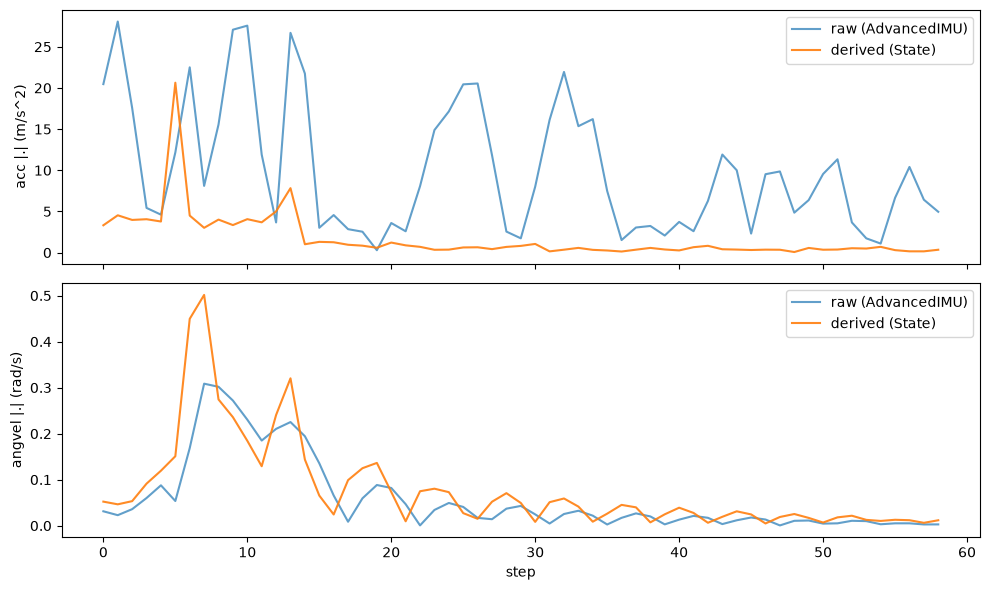

In [4]:
# re-runnable: drop a leftover imu_cmp from a previous run
try:
    imu.remove()
except Exception:
    pass

imu = AdvancedIMU("imu_cmp", env.beamng, env.ego,
                  gfx_update_time=1.0 / LIDAR_HZ,
                  is_send_immediately=True,
                  is_dir_world_space=False,
                  pos=(0, 0, 0.0),
                  dir=(1, 0, 0),    # sensor axis 1 = car forward
                  up=(0, 0, 1),     # sensor axis 2 = car up
                  smoother_strength=3.0)   # suppress suspension/road noise

# drive the car: a straight run, then a hard counter-steer to load the IMU.
# env.step() computes the derived IMU; imu.poll() reads the raw sensor.
env.beamng.control.resume()
raw_acc, raw_angvel, der_acc, der_angvel, states = [], [], [], [], []
for i in range(60):
    steering = -0.5 if i > 25 else 0.0
    env.step([steering, 0.6, 0.0])
    r = imu.poll()
    if isinstance(r, list):
        r = r[-1]
    # sensor frame [fwd, up, left] -> car frame [fwd, left, up]
    raw_acc.append([r["accSmooth"][0], r["accSmooth"][2], r["accSmooth"][1]])
    raw_angvel.append([r["angVelSmooth"][0], r["angVelSmooth"][2], r["angVelSmooth"][1]])
    der_acc.append(env._imu_acc.copy())
    der_angvel.append(env._imu_angvel.copy())
    states.append({k: np.asarray(v, float).copy() for k, v in env.ego.state.items()})
env.beamng.control.pause()

raw_acc = np.array(raw_acc, float)
raw_angvel = np.array(raw_angvel, float)
der_acc = np.array(der_acc, float)
der_angvel = np.array(der_angvel, float)

# denormalize the derived IMU (it is clipped to [-1, 1]); drop the first
# step (the derived IMU needs two State snapshots)
der_acc = der_acc * IMU_ACC_MAX
der_angvel = der_angvel * IMU_ANGVEL_MAX
raw_acc, der_acc = raw_acc[1:], der_acc[1:]
raw_angvel, der_angvel = raw_angvel[1:], der_angvel[1:]

print("airspeed range:",
      float(np.min([np.linalg.norm(s["vel"]) * 3.6 for s in states])),
      float(np.max([np.linalg.norm(s["vel"]) * 3.6 for s in states])))

def _report(name, raw, der):
    # the raw accelerometer reports the specific force (includes gravity and
    # suspension/road noise); the derived IMU is the smooth kinematic
    # d(vel)/dt. They are not expected to match per axis, but the magnitudes
    # should be in the same range.
    raw_mag = np.linalg.norm(raw, axis=1)
    der_mag = np.linalg.norm(der, axis=1)
    print(f"{name}: raw |.| mean {raw_mag.mean():.2f} / der |.| mean {der_mag.mean():.2f} | "
          f"raw std {raw.std(axis=0).round(2).tolist()} / der std {der.std(axis=0).round(2).tolist()}")

print("=== IMU raw vs derived (magnitude comparison) ===")
_report("acc    ", raw_acc, der_acc)
_report("angvel ", raw_angvel, der_angvel)

# chart: raw vs derived magnitude over time (mirrors the drift parity plot)
t = np.arange(len(raw_acc))
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(t, np.linalg.norm(raw_acc, axis=1), label="raw (AdvancedIMU)", alpha=0.7)
axes[0].plot(t, np.linalg.norm(der_acc, axis=1), label="derived (State)", alpha=0.9)
axes[0].set_ylabel("acc |.| (m/s^2)")
axes[0].legend()
axes[1].plot(t, np.linalg.norm(raw_angvel, axis=1), label="raw (AdvancedIMU)", alpha=0.7)
axes[1].plot(t, np.linalg.norm(der_angvel, axis=1), label="derived (State)", alpha=0.9)
axes[1].set_ylabel("angvel |.| (rad/s)")
axes[1].set_xlabel("step")
axes[1].legend()
plt.tight_layout()
plt.show()


## Drift telemetry replica: `drift_from_state` vs the game

The game's drift telemetry is **player-centric**: `drift.lua` tracks a single focused vehicle, so it cannot be used for N cars. The environment therefore computes drift per vehicle from the `State` sensor, mirroring the game's formulas (`drift.lua:230-231`):

```lua
currDegAngle = math.abs(yawDifference(tempVec, dirVec) * (180 / math.pi))
currDegAngleSign = vehData.vel:dot(up:cross(dirVec))
```

Two details matter for a true mirror. First, `yawDifference` is computed with `atan2` on the **horizontal (x, y) components** only, so the slip is a 2D yaw, not the full 3D angle: on a slope the 3D `arccos` would pick up pitch and drift from the game's number. Second, `vehicle.state` is a **snapshot** that is only refreshed by `sensors.poll()`; the parity hook polls it each frame, otherwise `drift_from_state` reads a frozen state and returns a flat line while the game's live Lua score keeps varying.

Before we trust that function replica for a whole group of cars, we verify it against the game's own numbers: run one scripted drift, and at every frame record both the Lua probe (`read_drift`) and `drift_from_state(ego.state)`. The run uses the **bx drift car** (the reference vehicle from notebook 01) so the scripted schedule and the game's drift setup match what was tuned there.


In [5]:
def read_drift(bng):
    """Drift telemetry from the game's Lua side, as a dict. The lua side packs
    the fields into a pipe-delimited string (booleans as 1/0); we split and
    cast here, so no json round-trip is needed."""
    chunk = (
        "local s = gameplay_drift_scoring.getScore() "
        "local b2s = function(x) return x and 1 or 0 end "
        "return string.format('%s|%s|%s|%s|%s|%s', "
        "s.potentialScore, s.score, "
        "b2s(gameplay_drift_drift.getIsDrifting()), "
        "b2s(gameplay_drift_general.getFrozen()), "
        "gameplay_drift_drift.getCurrDegAngleSigned(), "
        "gameplay_drift_drift.getAirSpeed())"
    )
    raw = bng.queue_lua_command(chunk, response=True)
    try:
        p = str(raw).split("|")
        return {"potentialScore": float(p[0]), "score": float(p[1]),
                "isDrifting": p[2] == "1", "frozen": p[3] == "1",
                "angle": float(p[4]), "airSpeed": float(p[5])}
    except (TypeError, ValueError, IndexError):
        print("read_drift: unexpected lua response:", repr(raw))
        return {"potentialScore": 0.0, "score": 0.0, "isDrifting": False,
                "frozen": False, "angle": 0.0, "airSpeed": 0.0}

# quick probe: confirm the dict comes back with real numbers
print(read_drift(env.beamng))


{'potentialScore': 0.0, 'score': 46.0, 'isDrifting': False, 'frozen': False, 'angle': 121.82853010968, 'airSpeed': 0.075013001222196}


In [6]:
# use the bx drift car: notebook 01's reference vehicle, so the parity
# schedule and the game's drift setup match what was tuned there
obs, info = env.reset(seed=0, options={"car": {"model": "bx", "part_config": "pro_drift_M"}})

# scripted drift (same schedule as notebook 01, arcade shift so no gear line)
def scripted_drift(hook, iterations=160):
    key = "Bridge15_C"
    env.beamng.control.resume()
    
    env.ego.teleport(env.waypoints[key].pos, rot_quat=env.waypoints[key].rot)
    time.sleep(0.25)
    env.ego.set_shift_mode("realistic_manual")
    time.sleep(0.22)
    # realistic manual gearbox
   
    env.beamng.control.pause()

    env.beamng.queue_lua_command('settings.setValue("enableDriftFreeroamCruising", true)')
    env.beamng.queue_lua_command('gameplay_drift_general.setContext("inFreeroam")')
    env.ego.ai.set_mode("none")
    env.ego.control(gear=1)

    for step in range(1, iterations):
        t, s, p = 0.0, 0.0, 0.0
        if step < 40:
            t, s = 0.4, 0.3
        elif step < 55:
            t, s = 1.0, -0.8
        elif step < 70:
            t, s = 1.0, -0.5
        elif step < 80:
            t, s = 0.5, -0.8
        elif step < 95:
            t, s = 0.55, -0.5
        elif step < 110:
            p, s = 0.8, -0.8
        elif step < 120:
            s = 0.4
        elif step < 125:
            t, s = 0.8, -0.99
        elif step >= 145:
            p = 0.9
        env.ego.control(throttle=t, steering=s, parkingbrake=p)
        hook(step)
        env.beamng.control.step(1)

    env.ego.control(throttle=0.0, steering=0.0)
    env.beamng.control.resume()

hist_game, hist_ours = [], []
def parity_hook(step):
    # refresh the State snapshot first: vehicle.state is only
    # updated by sensors.poll(), and without it drift_from_state
    # would read a frozen state and return a flat line
    env.ego.sensors.poll()
    hist_game.append(read_drift(env.beamng))
    hist_ours.append(drift_from_state(env.ego.state))

scripted_drift(parity_hook)
print(f"captured {len(hist_game)} frames")

# revert gearbox mode
env.ego.set_shift_mode("arcade")


[  175.52s] reset: start
[  175.53s] reset: first_time_setup done
[  176.53s] reset: resumed
[  176.76s] reset: scenario restarted
[  178.22s] reset: vehicle added
[  178.33s] reset: sensors set up
[  179.35s] reset: paused, polling sensors
[  179.37s] reset: sensors polled
[  179.38s] reset: done
captured 159 frames


frames: 159, moving: 129
max |angle diff|:    5.29 deg
max |airspeed diff|: 1.49 kph
isDrifting agreement: 86.8 %


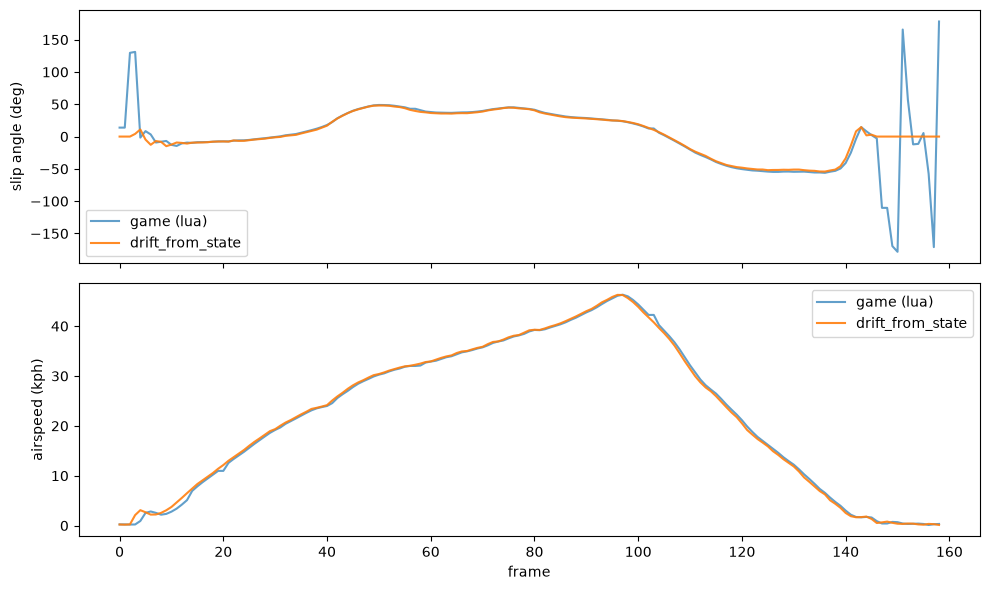

In [7]:
ang_g = np.array([g["angle"] for g in hist_game])
ang_o = np.array([o["angle"] for o in hist_ours])
sp_g = np.array([g["airSpeed"] for g in hist_game])
sp_o = np.array([o["airSpeed"] for o in hist_ours])
drift_g = np.array([g["isDrifting"] for g in hist_game])
drift_o = np.array([o["isDrifting"] for o in hist_ours])

mask = sp_g > 3.0   # compare only while the car is actually moving
print(f"frames: {len(hist_game)}, moving: {int(mask.sum())}")
print(f"max |angle diff|:    {np.max(np.abs(ang_g[mask] - ang_o[mask])):.2f} deg")
print(f"max |airspeed diff|: {np.max(np.abs(sp_g[mask] - sp_o[mask])):.2f} kph")
print(f"isDrifting agreement: {100 * (drift_g == drift_o).mean():.1f} %")

t = np.arange(len(hist_game))
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(t, ang_g, label="game (lua)", alpha=0.7)
axes[0].plot(t, ang_o, label="drift_from_state", alpha=0.9)
axes[0].set_ylabel("slip angle (deg)")
axes[0].legend()
axes[1].plot(t, sp_g, label="game (lua)", alpha=0.7)
axes[1].plot(t, sp_o, label="drift_from_state", alpha=0.9)
axes[1].set_ylabel("airspeed (kph)")
axes[1].set_xlabel("frame")
axes[1].legend()
plt.tight_layout()
plt.show()


The AI written drift function overlaps pretty well with what the game produces and it also works better at low speeds, where the slip angle diverges between the two functions, with the state-derived drifting function more stable which is a good thing.

## BEV: observation grid vs the raw point cloud

The `bev` observation is a 64x64 height grid built from the LiDAR point cloud: the car sits in the center, the grid spans +/-40 m around it, and it is rotated so the travel direction points up (the slip angle is compensated). Every cell holds the highest LiDAR return in it, clipped to [0, 1] with 0.5 = road level; empty cells also become 0.5, so the grid is a dense, bounded image. The car's own footprint is painted as a solid 1.0 block, rotated by the drift angle since the grid follows the travel direction, not the car's heading.

To verify, we freeze the game (pausing stops the LiDAR stream, so the shared-memory buffer stays static), read the `bev` channel of the observation, and recompute the grid independently from the raw point cloud and the cached `State` snapshot. The two must match exactly. Pass criteria:

- the recomputed grid matches `obs["bev"]` exactly
- all values are inside [0, 1]
- the majority of cells are at road level (the car is on a flat track)
- the car's footprint shows up as a bright (1.0) block in the center of the grid
- the drawn grid shows the track structure with the car in the center and travel direction up

Finally, we drive the car (a straight run, then a hard counter-steer to induce drift) and record the BEV grid every step to an AVI, like the LiDAR debug section of notebook 01: the bright car block should stay centered and rotate with the slip angle, while the track structure slides past.


In [8]:
# static frame: pause the game so the LiDAR shared-memory buffer is frozen
# between the observation read and the independent recompute
env.beamng.control.pause()

obs = env._get_obs()
bev_obs = obs["bev"]

# independent recompute from the raw point cloud: same inputs as _get_obs
# (the cached State snapshot and the drift derived from it)
pc = env._poll_lidar_points()
grid = np.nan_to_num(
    lidar_bev(pc, env.ego.state, drift_from_state(env.ego.state), n=BEV_N),
    nan=0.5)

# raw cloud sanity: every point must be inside the LiDAR range
rel = pc - np.asarray(env.ego.state["pos"], float)
print(f"points: {len(pc)}, max range {np.linalg.norm(rel, axis=1).max():.1f} m (limit {LIDAR_MAX_DIST})")
print(f"obs == recompute: {np.array_equal(bev_obs, grid)}")
print(f"shape {bev_obs.shape}, dtype {bev_obs.dtype}, min {bev_obs.min():.2f}, max {bev_obs.max():.2f} (must be inside [0, 1])")
road = np.abs(bev_obs - 0.5) <= 0.02
print(f"road-level cells: {100 * road.mean():.1f} % (expect the majority)")
center = bev_obs[BEV_N // 2 - 2 : BEV_N // 2 + 3, BEV_N // 2 - 2 : BEV_N // 2 + 3]
print(f"center 5x5 max: {center.max():.2f} (expect 1.0: the car's footprint)")


points: 43653, max range 39.5 m (limit 40.0)
obs == recompute: True
shape (64, 64), dtype float32, min 0.19, max 1.00 (must be inside [0, 1])
road-level cells: 64.5 % (expect the majority)
center 5x5 max: 1.00 (expect 1.0: the car's footprint)


##### Records an AVI of the BEV grid while driving, for debugging


In [9]:
# --- recording: write each frame to a temp folder, merge to an MJPEG .avi at the end ---
import glob
import tempfile

import cv2

def start_recording(prefix="bev"):
    """Create a temp frame folder. Returns (folder, save_mjpeg)."""
    d = tempfile.mkdtemp(prefix=prefix + "-frames-")
    print("frames ->", d)

    def save_mjpeg(path=None, fps=5):
        files = sorted(glob.glob(os.path.join(d, "frame_*.png")))
        if not files:
            print("no frames to save")
            return None

        out = path or os.path.join(d, "recording.avi")
        h, w = cv2.imread(files[0]).shape[:2]
        writer = cv2.VideoWriter(out, cv2.VideoWriter_fourcc(*"MJPG"), fps, (w, h))
        for f in files:
            writer.write(cv2.imread(f))
        writer.release()
        for f in files:
            os.remove(f)
        print("mjpeg ->", out, f"({len(files)} frames)")
        return out

    return d, save_mjpeg

print("start_recording defined")


start_recording defined


In [10]:
DEBUG_ITERS = 60
frames_dir, save_mjpeg = start_recording()

# BEV grid | colorbar
fig, (ax, cax) = plt.subplots(1, 2, figsize=(8.5, 7),
    gridspec_kw={"width_ratios": [3, 0.3]})

for step in range(1, DEBUG_ITERS + 1):
    # straight run, then a hard counter-steer to induce drift
    steering = -0.6 if step > 25 else 0.0
    obs, *_ = env.step([steering, 0.6, 0.0])
    bev = obs["bev"]

    ax.clear(); cax.clear()
    im = ax.imshow(bev,
                   extent=(-LIDAR_MAX_DIST, LIDAR_MAX_DIST, -LIDAR_MAX_DIST, LIDAR_MAX_DIST),
                   cmap="viridis", vmin=0.0, vmax=1.0)
    fig.colorbar(im, cax=cax, label="height (clipped to [0, 1])")
    ax.plot(0, 0, "r+", markersize=15, mew=2)
    kph = obs["airspeed"][0] * AIRSPEED_MAX_KPH
    slip = obs["drift_angle"][0] * ANGLE_MAX
    ax.set_title(f"step {step:3d}/{DEBUG_ITERS}  |  {kph:5.1f} kph  |  slip {slip:5.1f} deg")
    ax.set_xlabel("x (m): left -> right")
    ax.set_ylabel("y (m): behind -> forward")
    fig.savefig(os.path.join(frames_dir, f"frame_{step:04d}.png"), dpi=70)
plt.close(fig)

video_path = save_mjpeg()
if video_path:
    print("video:", video_path)


frames -> /tmp/bev-frames-2zuko1mh
mjpeg -> /tmp/bev-frames-2zuko1mh/recording.avi (60 frames)
video: /tmp/bev-frames-2zuko1mh/recording.avi


## Making the environment reusable

Both scaling options (N vehicles in one instance, N instances) need the same per-vehicle logic: the vehicle, its sensor suite, the observation builder, the failure check, and the reward. We extract it into a `VehicleAgent` class. The vector environment is then just N of these, stepped in lockstep by one shared `step(1)`.

The BEV helpers (`car_rotation`, `lidar_bev`) are module-level functions in `beamng_tech.py`, imported by the notebook and shared by the single-vehicle env and the agent - no redefinition here. The max-height-per-cell step uses `np.maximum.at` (one O(N) pass) instead of an O(N log N) `argsort` + `unique` + `reduceat`, which is ~3-4x faster on a full point cloud; this is the reason the `obs+bev` slice shrinks once the socket round trips are amortized.


In [11]:
class VehicleAgent:
    """One vehicle + its sensor suite + the per-vehicle obs/reward helpers.

    Shared by the single-vehicle env and the vector env: the vector env is
    just N of these, advanced by one shared beamng.control.step(1).

    The observation path mirrors BeamNGTechEnv exactly, so the single- and
    vector-env observations are computed identically (a fair comparison of
    the two in terms of the observations they produce):
    - imu_acc/imu_angvel are DERIVED from two State snapshots (_derive_imu),
      no AdvancedIMU round trip
    - the LiDAR point cloud is read from shared memory, skipping the colour
      buffer (_poll_lidar_points)
    """

    def __init__(self, name, beamng, vehicle):
        self.name = name
        self.beamng = beamng
        self.ego = vehicle
        self.electrics = None
        self.damage = None
        self.lidar = None
        self.reset_reward_state()

    def reset_reward_state(self):
        self.previous = dict(speed=0.0, score=0.0, damage=0.0)
        self.current = dict(speed=0.0, score=0.0, damage=0.0)
        self._score_total = 0.0
        # a freshly added vehicle has an empty state snapshot until the
        # first poll; default to 0.0 so __init__ does not KeyError
        self._t0 = self.ego.state.get("time", 0.0)
        # previous State snapshot for the derived IMU (None until the first
        # poll, so the first derived reading is zero, like the single env)
        self._prev_state = None

    def setup_sensors(self):
        self.ego.set_shift_mode("arcade")
        self.electrics = Electrics()
        self.damage = Damage()
        self.ego.sensors.attach("electrics", self.electrics)
        self.ego.sensors.attach("damage", self.damage)
        # no AdvancedIMU: imu_acc/imu_angvel are derived from the State sensor
        # in _derive_imu, mirroring the single-vehicle env (one less round trip)
        self.lidar = Lidar(f"roof_{self.name}", self.beamng, self.ego,
            requested_update_time=1.0 / LIDAR_HZ,
            pos=(0.0, 0.0, 1.5),
            vertical_resolution=LIDAR_RES_V,
            vertical_angle=LIDAR_V_ANGLE,
            frequency=LIDAR_HZ,
            max_distance=LIDAR_MAX_DIST,
            density=LIDAR_DENSITY,
            is_360_mode=True,
            is_rotate_mode=False,
            is_using_shared_memory=True,
            is_visualised=False,
            is_streaming=True,
        )

    def apply_action(self, action):
        steering, combined, parkingbrake = (float(v) for v in action)
        throttle = combined if combined > 0.0 else 0.0
        brake = -combined if combined < 0.0 else 0.0
        self.ego.control(
            steering=steering,
            throttle=throttle,
            brake=brake,
            parkingbrake=0.0 if parkingbrake < 0.0 else parkingbrake,
        )

    def _derive_imu(self, state):
        """Accel and angular velocity from two consecutive State snapshots,
        mirroring BeamNGTechEnv._derive_imu (replaces the AdvancedIMU poll).

        Car frame, [fwd, left, up] order: acc = d(vel)/dt (no gravity offset),
        angvel = rotation-vector rate in rad/s. Returns zeros until the second
        snapshot, or if the tick did not advance (stale read).
        """
        prev = self._prev_state
        # copy the fields: ego.state is mutated in place by the next poll, so
        # a reference would make prev identical to state (dt = 0)
        self._prev_state = {
            "vel": np.array(state["vel"], float),
            "dir": np.array(state["dir"], float),
            "up": np.array(state["up"], float),
            "time": float(state["time"]),
        }
        if prev is None:
            return np.zeros(3, dtype=np.float32), np.zeros(3, dtype=np.float32)
        dt = float(state["time"]) - float(prev["time"])
        if dt < 0.04:
            return np.zeros(3, dtype=np.float32), np.zeros(3, dtype=np.float32)
        R = car_rotation(state)
        v_car = R.T @ np.asarray(state["vel"], float)
        v_car_prev = car_rotation(prev).T @ np.asarray(prev["vel"], float)
        acc = (v_car - v_car_prev) / dt
        dR = R.T @ car_rotation(prev)
        skew = 0.5 * np.array([
            dR[2, 1] - dR[1, 2],
            dR[0, 2] - dR[2, 0],
            dR[1, 0] - dR[0, 1],
        ])
        theta = float(np.arccos(np.clip((np.trace(dR) - 1.0) / 2.0, -1.0, 1.0)))
        if theta > 1e-4:
            angvel = skew * (theta / np.sin(theta)) / dt
        else:
            angvel = skew / dt
        acc = np.clip(acc / IMU_ACC_MAX, -1.0, 1.0)
        angvel = np.clip(angvel / IMU_ANGVEL_MAX, -1.0, 1.0)
        return acc.astype(np.float32), angvel.astype(np.float32)

    def _poll_lidar_points(self):
        """Point cloud from shared memory, skipping the colour buffer (unused).
        Mirrors BeamNGTechEnv._poll_lidar_points / Lidar._convert_binary_to_array:
        in streaming mode the game writes the point count as the last float."""
        shmem = self.lidar.point_cloud_shmem
        buf = np.frombuffer(shmem.read(self.lidar.point_cloud_shmem_size),
                            dtype=np.float32)
        n = int(buf[-1])
        if n <= 0 or n * 3 > len(buf) - 1:
            return np.empty((0, 3), dtype=np.float32)
        return buf[: 3 * n].reshape(-1, 3).copy()

    def get_obs(self):
        self.ego.sensors.poll()
        e = self.ego.sensors["electrics"]
        drift = drift_from_state(self.ego.state)
        # derived IMU from State snapshots (mirrors the single env; no round trip)
        acc, angvel = self._derive_imu(self.ego.state)
        if drift["airSpeed"] <= 1.0:
            acc = np.zeros(3, dtype=np.float32)
            angvel = np.zeros(3, dtype=np.float32)
        bev = np.nan_to_num(lidar_bev(self._poll_lidar_points(),
                                      self.ego.state, drift, n=BEV_N),
                            nan=0.5)
        self.current["speed"] = drift["airSpeed"]
        self._score_total += drift["scoreAdded"]
        self.current["score"] = self._score_total
        dmg = self.ego.sensors["damage"]
        self.current["damage"] = dmg.get("damage", 0.0) if isinstance(dmg, dict) else 0.0
        return {
            "rpm":         np.clip(np.array([e["rpm"] / e["maxrpm"]], np.float32), 0.0, 1.0),
            "imu_acc":     acc,
            "imu_angvel":  angvel,
            "drift_angle": np.clip(np.array([drift["angle"] / ANGLE_MAX], np.float32), -1.0, 1.0),
            "airspeed":    np.array([min(AIRSPEED_MAX_KPH, drift["airSpeed"]) / AIRSPEED_MAX_KPH], np.float32),
            "is_shifting": np.array([1.0 if e["is_shifting"] else 0.0], np.float32),
            "bev":         bev,
        }

    def check_failure(self):
        """Return (failed: bool, reason: str) from the Damage sensor poll."""
        dmg = self.ego.sensors["damage"]
        if not isinstance(dmg, dict):
            return False, ""
        overall = dmg.get("damage", 0.0)
        tire_flat = dmg.get("lowpressure")
        if overall > DAMAGE_LIMIT:
            return True, f"damage={overall:.3f}"
        if tire_flat:
            return True, f"tire flat (lowpressure={tire_flat})"
        return False, ""

    def compute_reward(self):
        """Same formula as BeamNGTechEnv._compute_reward, per vehicle."""
        drift_delta = max(0.0, self.current["score"] - self.previous["score"])
        drift_reward = min(0.8, drift_delta * 0.01)
        speed_delta = max(0.0, self.current["speed"] - self.previous["speed"])
        speed_reward = min(0.2, speed_delta * 0.01)
        dmg_delta = max(0.0, self.current["damage"] - self.previous["damage"])
        dmg_reward = max(-1.0, -dmg_delta * 0.001)
        slow_reward = (-0.05 * (MIN_SPEED - self.current["speed"])
                       if self.current["speed"] < MIN_SPEED else 0.0)
        # copy, not a reference: get_obs mutates self.current in place,
        # so a reference would make every delta zero after the first step
        self.previous = dict(self.current)
        return drift_reward + dmg_reward + speed_reward + slow_reward

    def respawn(self, waypoint):
        self.ego.teleport(waypoint.pos, rot_quat=waypoint.rot)
        self.reset_reward_state()

print("VehicleAgent defined")


VehicleAgent defined


To verify let's drive a fresh car (spawned next to the env's ego) with random actions for 50 frames. Pass criteria: every observation key matches the env's `observation_space`, every value is inside its bounds, rewards are finite, and the car actually moves when given random throttle.


In [12]:
# spawn a test car next to the env's ego
# re-runnable: a previous (failed) run may have left it behind
if "agent_test" in env.scenario.vehicles:
    env.scenario.remove_vehicle(env.scenario.vehicles["agent_test"])
rng = np.random.default_rng(0)
key = list(env.waypoints.keys())[int(rng.integers(len(env.waypoints)))]
test_car = Vehicle("agent_test", license="AGT0", color="Blue",
                   **DRIFT_CARS_6SPEED[int(rng.integers(len(DRIFT_CARS_6SPEED)))])
env.scenario.add_vehicle(test_car, pos=env.waypoints[key].pos,
                         rot_quat=env.waypoints[key].rot)

agent = VehicleAgent(test_car.vid, env.beamng, test_car)
agent.setup_sensors()
time.sleep(1)

env.beamng.control.resume()
ok = True
min_speed = 0.0
for i in range(50):
    agent.apply_action(env.action_space.sample())
    env.beamng.control.step(1)
    o = agent.get_obs()
    for k, space in env.observation_space.spaces.items():
        if not space.contains(o[k]):
            print(f"OUT OF BOUNDS: {k} = {o[k]}")
            ok = False
    r = agent.compute_reward()
    if not np.isfinite(r):
        print(f"NON-FINITE reward at step {i}: {r}")
        ok = False
    min_speed = max(min_speed, float(o["airspeed"][0]) * AIRSPEED_MAX_KPH)
env.beamng.control.pause()

print(f"obs keys match: {sorted(o.keys()) == sorted(env.observation_space.spaces.keys())}")
print(f"all values in bounds: {ok}")
print(f"max airspeed seen: {min_speed:.1f} kph (should be > 0 with random throttle)")
env.scenario.remove_vehicle(test_car)


/home/admin/Projects/beamng-drift-project/drift-ai/src/env/gymnasium/beamng_tech_env/envs/beamng_tech.py:121: RuntimeWarning: invalid value encountered in subtract
  p = (pc - np.asarray(state["pos"], float)) @ R   # [fwd, left, up]
/home/admin/Projects/beamng-drift-project/drift-ai/src/env/gymnasium/beamng_tech_env/envs/beamng_tech.py:124: RuntimeWarning: invalid value encountered in cast
  ix = ((dx + range_m) * n / (2 * range_m)).astype(int)
/home/admin/Projects/beamng-drift-project/drift-ai/src/env/gymnasium/beamng_tech_env/envs/beamng_tech.py:125: RuntimeWarning: invalid value encountered in cast
  iy = ((dy + range_m) * n / (2 * range_m)).astype(int)


obs keys match: True
all values in bounds: True
max airspeed seen: 3.3 kph (should be > 0 with random throttle)


## Spawn pattern

The spawn pattern comes from the BeamNG platooning example: build N `Vehicle` objects, add each to the scenario at a fixed position with a shared heading, and `scenario.make` / `load` / `start` happen once for the whole group. We replace the fixed formation positions with N mutually distant waypoints, picked greedily (each new pick is the one farthest from all previous picks), so the cars' 40 m LiDAR cones do not overlap.


In [13]:
def pick_waypoints(waypoints, n, rng):
    """Greedy max-min: each new pick is far from all previous picks."""
    keys = list(waypoints.keys())
    picked = [keys[rng.integers(len(keys))]]
    while len(picked) < n:
        best, best_d = None, -1.0
        for key in keys:
            if key in picked:
                continue
            d = min(
                sum((a - b) ** 2 for a, b in zip(waypoints[key].pos, waypoints[p].pos))
                for p in picked
            )
            if d > best_d:
                best, best_d = key, d
        picked.append(best)
    return picked

def spawn_group(scenario, beamng, n, waypoints, rng):
    keys = pick_waypoints(waypoints, n, rng)
    vehicles = []
    for i, key in enumerate(keys):
        car = DRIFT_CARS_6SPEED[int(rng.integers(len(DRIFT_CARS_6SPEED)))]
        v = Vehicle(f"ego_{i}", license=f"DRF{i:02d}", color="Red", **car)
        scenario.add_vehicle(v, pos=waypoints[key].pos, rot_quat=waypoints[key].rot)
        vehicles.append(v)
    return vehicles

print("pick_waypoints / spawn_group defined")


pick_waypoints / spawn_group defined


To verify, we pick 4 waypoints and print every distance between pairs. Pass criteria: all distances above `2 * LIDAR_MAX_DIST` (80 m), so no two LiDAR cones overlap.


In [14]:
rng = np.random.default_rng(0)
keys = pick_waypoints(env.waypoints, 4, rng)
print("picked waypoints:")
for k in keys:
    print(f"  {k}: {env.waypoints[k].pos}")

dists = []
for i in range(len(keys)):
    for j in range(i + 1, len(keys)):
        d = np.linalg.norm(np.asarray(env.waypoints[keys[i]].pos, float)
                           - np.asarray(env.waypoints[keys[j]].pos, float))
        dists.append(d)
        print(f"  {keys[i]} <-> {keys[j]}: {d:.1f} m")

print(f"\nmin pairwise distance: {min(dists):.1f} m (need > {2 * LIDAR_MAX_DIST:.0f} m)")
assert min(dists) > 2 * LIDAR_MAX_DIST, "LiDAR cones would overlap"
print("OK: LiDAR cones do not overlap")


picked waypoints:
  dirttrack_15: (780.552734375, 17.607057571411133, 149.15365600585938)
  overpass_S_B_14: (-1138.4337158203125, -777.951904296875, 121.1657485961914)
  wp_town12: (-756.2529907226562, 661.3834838867188, 106.1199722290039)
  tunnel_NE_A_15: (1060.4464111328125, -1212.2135009765625, 165.50730895996094)
  dirttrack_15 <-> overpass_S_B_14: 2077.5 m
  dirttrack_15 <-> wp_town12: 1666.8 m
  dirttrack_15 <-> tunnel_NE_A_15: 1261.4 m
  overpass_S_B_14 <-> wp_town12: 1489.3 m
  overpass_S_B_14 <-> tunnel_NE_A_15: 2241.8 m
  wp_town12 <-> tunnel_NE_A_15: 2610.4 m

min pairwise distance: 1261.4 m (need > 80 m)
OK: LiDAR cones do not overlap


## Per-vehicle sensors

Each car gets the same suite the single-vehicle environment uses: `Electrics`, `Damage`, `AdvancedIMU`, and a shared-memory 360-degree `Lidar` (plus the auto-attached `State` sensor, which `drift_from_state` reads). Sensor names are unique per vehicle (`imu_<name>`, `roof_<name>`).

To verify, we spawn 4 cars, wrap each in a `VehicleAgent`, attach the suite, let the game run 10 frames, then poll every agent. Pass criteria: every car returns a valid observation with a non-empty BEV.


In [15]:
# re-runnable: drop leftover group cars from a previous run
for vid in [v for v in env.scenario.vehicles if v.startswith("ego_")]:
    env.scenario.remove_vehicle(env.scenario.vehicles[vid])
vehicles = spawn_group(env.scenario, env.beamng, 4, env.waypoints,
                       np.random.default_rng(1))
agents = []
for v in vehicles:
    a = VehicleAgent(v.vid, env.beamng, v)
    a.setup_sensors()
    agents.append(a)
time.sleep(1)

# let the game run a few frames so the sensors produce data
env.beamng.control.resume()
for _ in range(10):
    env.beamng.control.step(1)
env.beamng.control.pause()

print(f"{'car':8s} {'rpm':>6s} {'airspeed':>9s} {'bev cells':>9s}")
for a in agents:
    o = a.get_obs()
    n_cells = int((o["bev"] != 0.5).sum())
    print(f"{a.name:8s} {o['rpm'][0]:6.3f} {o['airspeed'][0] * AIRSPEED_MAX_KPH:8.1f} {n_cells:9d}")
    assert o["bev"].shape == (BEV_N, BEV_N)
    assert n_cells > 0, f"{a.name}: empty BEV"
print("OK: every car returns a valid observation with LiDAR data")


car         rpm  airspeed bev cells
ego_0     0.094      0.0      1345
ego_1     0.124      0.0       694
ego_2     0.132      0.0       553
ego_3     0.122      0.0       603
OK: every car returns a valid observation with LiDAR data


## The Vector training environment

The agent also built a custom `gym.vector.VectorEnv` mapping each vehicle to one sub-environment. 

Key properties:

- **One `step(1)` round trip is shared by all N vehicles.** The determinism anchor is paid once per vector step, not N times.
- **Lockstep for free.** Gymnasium `VectorEnv` requires all sub-environments to step in sync; a single shared physics tick gives that.
- **Terminated sub-environments must not stall the step.** A crashed car keeps existing in the simulation, so the environment respawns it (teleport to a fresh waypoint) and the group stays intact.
- **`reset()` restarts the scenario once**, not N times.

The env is configured by a **port** (default 25252) - no game objects are passed in. On setup it checks whether BeamNG is listening on that port: if so, it connects and reuses the loaded map (loading the drift map first if a different one is up); if not, it launches a fresh instance there. `close()` releases the connection without quitting the shared game.


In [16]:
MAP_LEVEL = "west_coast_usa"
MAP_NAME = "Gymnasium"

def port_listening(port, host="localhost", timeout=1.0):
    """True if something is accepting TCP connections on host:port."""
    import socket
    try:
        with socket.create_connection((host, port), timeout=timeout):
            return True
    except OSError:
        return False

class BeamNGTechVectorEnv(gym.vector.VectorEnv):
    metadata = {"render_modes": ["human"], "render_fps": FPS}

    def __init__(self, num_envs, port=25252, render_mode=None):
        self.num_envs = num_envs
        self.port = port
        single_obs = {
            "rpm":         spaces.Box(low=0.0,  high=1.0, shape=(1,),           dtype=np.float32),
            "imu_acc":     spaces.Box(low=-1.0, high=1.0, shape=(3,),           dtype=np.float32),
            "imu_angvel":  spaces.Box(low=-1.0, high=1.0, shape=(3,),           dtype=np.float32),
            "drift_angle": spaces.Box(low=-1.0, high=1.0, shape=(1,),           dtype=np.float32),
            "airspeed":    spaces.Box(low=0.0,  high=1.0, shape=(1,),           dtype=np.float32),
            "is_shifting": spaces.Box(low=0.0,  high=1.0, shape=(1,),           dtype=np.float32),
            "bev":         spaces.Box(low=0.0,  high=1.0, shape=(BEV_N, BEV_N), dtype=np.float32),
        }
        single_action = spaces.Box(low=np.array([-1.0, -1.0, -1.0], dtype=np.float32),
                                   high=np.array([1.0, 1.0, 1.0], dtype=np.float32))
        self.observation_space = gym.vector.utils.batch_space(spaces.Dict(single_obs), num_envs)
        self.action_space = gym.vector.utils.batch_space(single_action, num_envs)

        assert render_mode is None or render_mode in self.metadata["render_modes"]
        self.render_mode = render_mode

        self.beamng = None
        self.scenario = None
        self.waypoints = None
        self.agents = []
        self._rng = np.random.default_rng()

    def _ensure_setup(self):
        """Connect to the game on self.port and make sure the drift map is
        loaded. Idempotent: a second call on a set-up env is a no-op.

        The setup is driven by whatever is on the port:
        - game already listening: connect, and reuse the loaded map (loading
          the drift map first if a different one is up)
        - nothing on the port: open() launches a fresh instance there
        """
        if self.scenario is not None and self.beamng is not None and self.beamng.connection:
            return

        if port_listening(self.port):
            print(f"[vector env] BeamNG is listening on port {self.port}; connecting")
        else:
            print(f"[vector env] nothing on port {self.port}; launching BeamNG")

        self.beamng = BeamNGpy("localhost", self.port)
        self.beamng.open()

        current = None
        try:
            current = self.beamng.scenario.get_current()
        except Exception:
            current = None
        if current is not None and getattr(current, "name", None) == MAP_NAME:
            # the drift map is already loaded: reuse it
            self.scenario = current
        else:
            self.scenario = Scenario(MAP_LEVEL, MAP_NAME)
            self.scenario.make(self.beamng)
            self.beamng.scenario.load(self.scenario)
            self.scenario.start()
        self.waypoints = {w.name: w for w in self.scenario.find_waypoints()}

        # one-time game config (idempotent, safe to re-apply on a reused map)
        self.beamng.queue_lua_command('''
            settings.setValue("steeringAutocenterEnabled", false)
            settings.setValue("steeringSlowdownEnabled", false)
            settings.setValue("steeringStabilizationEnabled", false)
            settings.setValue("steeringUndersteerReductionEnabled", false)
            settings.setValue("steeringLimitEnabled", false)
            settings.setValue("autoClutch", true)
            settings.setValue("autoThrottle", true)
            settings.setValue("absBehavior", "off")
        ''')
        self.beamng.settings.change("GraphicDisplayMode", "Windowed")
        self.beamng.settings.change("GraphicDisplayResolutions", "640 480")
        self.beamng.settings.apply_graphics()
        self.beamng.queue_lua_command('be:setPhysicsDeterministic(true)')
        self.beamng.queue_lua_command('settings.setValue("fpsLimit", 20)')
        self.beamng.queue_lua_command('settings.setValue("fpsLimitEnabled", true)')
        self.beamng.queue_lua_command('be:setPhysicsSpeedFactor(1)')

        time.sleep(1)
        self.beamng.control.pause()

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self._rng = np.random.default_rng(seed)
        self._ensure_setup()

        self.beamng.control.resume()
        time.sleep(1)
        # remove every vehicle in the scenario (previous agents, the
        # single-vehicle env's ego, leftovers from earlier sections)
        for v in list(self.scenario.vehicles.values()):
            self.scenario.remove_vehicle(v)
        self.agents = []
        # Scenario.restart() (not the API one): it only needs scenario.bng,
        # so it works whether the map was loaded here or reused from the port
        self.scenario.restart()

        vehicles = spawn_group(self.scenario, self.beamng, self.num_envs,
                               self.waypoints, self._rng)
        self.agents = [VehicleAgent(v.vid, self.beamng, v) for v in vehicles]
        for a in self.agents:
            a.setup_sensors()
        time.sleep(1)
        self.beamng.control.pause()

        obs = self._stack_obs()
        for a in self.agents:
            a.reset_reward_state()
        return obs, {}

    def step(self, actions):
        for i, a in enumerate(self.agents):
            a.apply_action(actions[i])

        # one shared physics tick advances every car
        self.beamng.control.step(1)

        obs = self._stack_obs()
        rewards = np.zeros(self.num_envs, dtype=np.float32)
        terminated = np.zeros(self.num_envs, dtype=bool)
        truncated = np.zeros(self.num_envs, dtype=bool)
        for i, a in enumerate(self.agents):
            rewards[i] = a.compute_reward()
            terminated[i], _ = a.check_failure()
            truncated[i] = (a.ego.state["time"] - a._t0) > EPISODE_TIMEOUT
            if terminated[i] or truncated[i]:
                keys = list(self.waypoints.keys())
                a.respawn(self.waypoints[keys[int(self._rng.integers(len(keys)))]])
        return obs, rewards, terminated, truncated, {}

    def _stack_obs(self):
        obs_list = [a.get_obs() for a in self.agents]
        return {k: np.stack([o[k] for o in obs_list]) for k in obs_list[0]}

    def close(self):
        # release the connection without quitting the (possibly shared) game
        if self.beamng is not None:
            self.beamng.disconnect()

print("BeamNGTechVectorEnv defined")


BeamNGTechVectorEnv defined


## Validation

`gymnasium.utils.env_checker.check_env` (gymnasium 1.2.2) requires a `gym.Env` subclass and assumes a single, unbatched environment, so it cannot validate a custom `VectorEnv` (this version has no `check_vector_env`). We check the vector contract manually instead.


To verify, we can reset with 2 sub-environments, check the observation shapes, then run 30 random steps.

In [17]:
venv = BeamNGTechVectorEnv(2)
obs, info = venv.reset(seed=0)
print("reset ok, obs shapes:")
for k, v in obs.items():
    print(f"  {k:12s} {v.shape}")
assert all(v.shape[0] == 2 for v in obs.values())

N_STEPS = 30
for i in range(N_STEPS):
    obs, rewards, terminated, truncated, info = venv.step(venv.action_space.sample())
assert obs["bev"].shape == (2, BEV_N, BEV_N)
assert rewards.shape == (2,)
assert terminated.shape == (2,)
assert truncated.shape == (2,)
print(f"\n{N_STEPS} random steps ok")
print(f"last rewards:     {rewards}")
print(f"last terminated:  {terminated}")
print(f"last truncated:   {truncated}")
print(f"last airspeeds:   {np.round(obs['airspeed'].ravel() * AIRSPEED_MAX_KPH, 1)} kph")


[vector env] BeamNG is listening on port 25252; connecting
reset ok, obs shapes:
  rpm          (2, 1)
  imu_acc      (2, 3)
  imu_angvel   (2, 3)
  drift_angle  (2, 1)
  airspeed     (2, 1)
  is_shifting  (2, 1)
  bev          (2, 64, 64)

30 random steps ok
last rewards:     [-0.4737122  -0.49298918]
last terminated:  [False False]
last truncated:   [False False]
last airspeeds:   [0.5 0.1] kph


In [18]:
def check_vector_env_contract(venv, n_steps=5):
    """gymnasium 1.2.2's check_env() requires a gym.Env subclass and assumes
    a single, unbatched env, so it cannot validate a custom VectorEnv (this
    version has no check_vector_env). Check the vector contract manually:
    batched reset/step shapes, dtypes, and value bounds."""
    def check_obs(obs, tag):
        for k, space in venv.observation_space.spaces.items():
            assert k in obs, f"{tag}: missing obs key {k}"
            # batch_space already prepends the env dim to each subspace
            assert obs[k].shape == tuple(space.shape), f"{tag} {k}: shape {obs[k].shape} != {tuple(space.shape)}"
            assert obs[k].dtype == space.dtype, f"{tag} {k}: dtype {obs[k].dtype} != {space.dtype}"
            assert np.all(obs[k] >= space.low) and np.all(obs[k] <= space.high), f"{tag} {k}: out of bounds"

    obs, info = venv.reset(seed=0)
    assert isinstance(info, dict), "reset info must be a dict"
    check_obs(obs, "reset")

    for _ in range(n_steps):
        obs, rewards, terminated, truncated, info = venv.step(venv.action_space.sample())
        assert rewards.shape == (venv.num_envs,) and rewards.dtype == np.float32, "rewards shape/dtype"
        assert terminated.shape == (venv.num_envs,) and terminated.dtype == np.bool_, "terminated shape/dtype"
        assert truncated.shape == (venv.num_envs,) and truncated.dtype == np.bool_, "truncated shape/dtype"
        check_obs(obs, "step")
    print("vector env contract OK: shapes, dtypes, bounds all valid")

check_vector_env_contract(venv)

vector env contract OK: shapes, dtypes, bounds all valid


## How FPS scales with the number of vehicles

The single `step(1)` round trip is amortized across N vehicles, and the LiDAR and drift reads cost zero round trips, so each added vehicle adds roughly one bundled sensor poll and one fire-and-forget control.

We measure transitions per second (N times the vector FPS) for N = 1, 2, 4, 8. The first environment pays the map load; the rest reuse the loaded map.


[vector env] BeamNG is listening on port 25252; connecting
N=1: 10 transitions/s (10.0 vector FPS)
[vector env] BeamNG is listening on port 25252; connecting
N=2: 10 transitions/s (5.0 vector FPS)
[vector env] BeamNG is listening on port 25252; connecting
N=4: 10 transitions/s (2.5 vector FPS)
[vector env] BeamNG is listening on port 25252; connecting
N=8: 9 transitions/s (1.1 vector FPS)


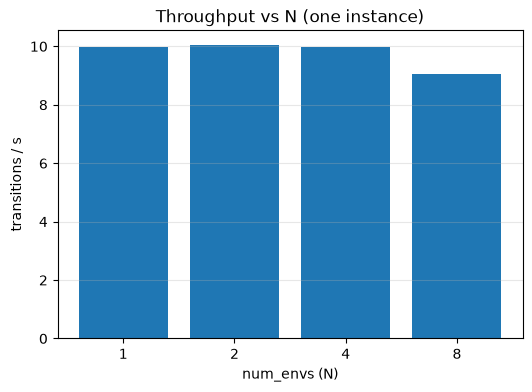

In [19]:
def benchmark(n, n_steps=50):
    # each env connects to the game on the default port and reuses the
    # already-loaded map; close() releases the connection (it does not quit
    # the shared game), so the next N can connect in its place
    v = BeamNGTechVectorEnv(n)
    v.reset(seed=0)
    time.sleep(2)   # let the sensors warm up
    t0 = time.perf_counter()
    for _ in range(n_steps):
        v.step(v.action_space.sample())
    dt = time.perf_counter() - t0
    v.close()
    return (n_steps * n) / dt   # transitions per second

results = {}
for n in [1, 2, 4, 8]:
    results[n] = benchmark(n)
    print(f"N={n}: {results[n]:.0f} transitions/s ({results[n] / n:.1f} vector FPS)")

plt.figure(figsize=(6, 4))
plt.bar([str(n) for n in results], list(results.values()))
plt.xlabel("num_envs (N)")
plt.ylabel("transitions / s")
plt.title("Throughput vs N (one instance)")
plt.grid(axis="y", alpha=0.3)
plt.show()


The curve is nearly flat, the single game thread is saturated, which means the only chance of finding an improvement from this point is Option B.


## Option B: N instances with `AsyncVectorEnv` (scale-out)

Option A's scaling is sublinear: every round trip still serializes on the one socket and one game thread, so throughput is bounded by that single thread (section 9 shows the curve flattening). When one machine's CPU is the bottleneck, the scale-out path is to run N BeamNG.tech processes, each driving one car, and let Gymnasium parallelize them across cores:

```python
from gymnasium.vector import AsyncVectorEnv

def make_env(port):
    return lambda: BeamNGTechEnv(host="localhost", port=port)

env = AsyncVectorEnv([make_env(25252 + i) for i in range(n)],
                     shared_memory=True)
```

Each instance is launched on its own port with `BeamNGpy("localhost", 25252 + i).open()`. The existing single-vehicle `BeamNGTechEnv` works as the sub-environment once a `host`/`port` parameter is added (it currently hardcodes `localhost:25252`).

**Trade-offs**

- **True parallelism:** each process has its own socket and its own game thread, so the per-step round trips (control, step, sensor poll) are processed concurrently on N cores instead of serializing on one. Episodes are also independent (no lockstep, no respawn coupling).
- **Cost:** N times the RAM and GPU load, and N map loads at startup.

This option was not attempted, but it still remains an option to explore later.

## Wrap-up

What this notebook built, block by block:

| Block | Where it lands in `src/` |
|---|---|
| `car_rotation` / `lidar_bev` (module level) | `beamng_tech.py` (replaces the env methods) |
| `VehicleAgent` | new `envs/vehicle_agent.py` |
| `pick_waypoints` / `spawn_group` | new `envs/spawn.py` |
| `BeamNGTechVectorEnv` | new `envs/beamng_tech_vector.py` |
| registration | `__init__.py`: `beamng_tech_env/BeamNGTechVector-v0.39` |

`BeamNGTechEnv` can then be refactored to use `VehicleAgent` internally, so the single- and vector environments share one code path.

**Next steps**

At this point we have a sufficiently fast training environment, we will now attempt to train some models and we'll finally learn if we designed the reward function well.  
We'll possibly scale with Option B later, I will likely also explore an Option C - how to utilize multiple GPUs for the game.  
I have a feeling the game's mostly limited by the CPU, that's why I'm not rushing to explore this option right now and I am pleased with the optimizations found by the AI agent.
